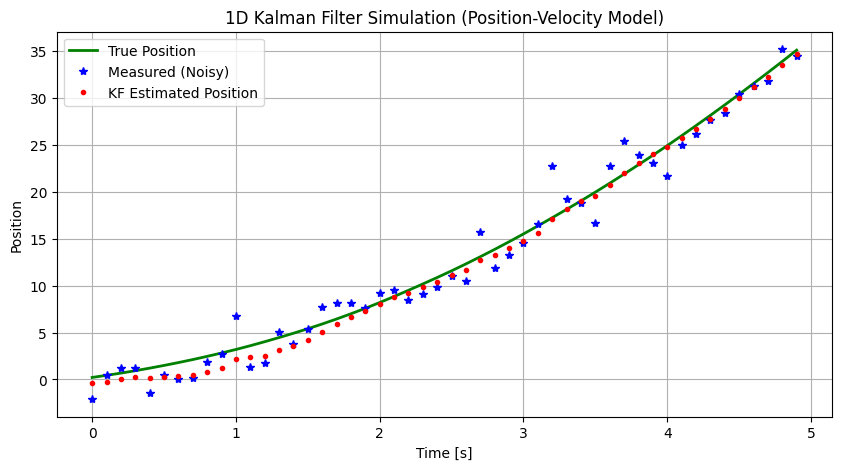

In [1]:
### JHU INTRODUCTION TO AUGMENTED REALITY (2026)
### Q1e. 1D Kalman Filter for Position and Velocity Estimation
###
###
###
### Complete the Kalman Filter update step below (marked with ???) to
### estimate the position and velocity of an object moving in 1D with
### constant acceleration.
### Use the provided system model, process noise, and measurement noise parameters.

import numpy as np
import matplotlib.pyplot as plt

# Simulation parameters
dt = 0.1        # time step
num_steps = 50

# True system model: constant velocity model in 1D
A = np.array([[1, dt],
              [0, 1]])  # state transition matrix
B = np.array([[0.5*dt**2],
              [dt]])     # control matrix (for acceleration input)
H = np.array([[1, 0]])   # measurement matrix

# Process and measurement noise
sigma_process = 0.5
sigma_measure = 2.0
Q = sigma_process**2 * np.array([[dt**4/4, dt**3/2],
                                 [dt**3/2, dt**2]])  # process noise covariance
R = np.array([[sigma_measure**2]])                   # measurement noise covariance

# Initialize
x_true = np.array([[0.0], [1.0]])   # true initial state (position, velocity)
x_est = np.array([[0.0], [0.0]])    # estimated initial state
P = np.eye(2) * 1.0                 # initial covariance

# Plotting arrays
true_positions = []
measured_positions = []
estimated_positions = []

# Simulation loop
for k in range(num_steps):
    # True system evolution
    a = 2.0  # constant acceleration
    process_noise = np.random.multivariate_normal([0.1, 0], Q).reshape(2, 1)
    x_true = A @ x_true + B * a + process_noise

    # Noisy measurement
    measurement_noise = np.random.normal(0, sigma_measure)
    z = H @ x_true + measurement_noise

    # Kalman Filter steps

    # 1. Prediction
    x_pred = A @ x_est + B * a
    P_pred = A @ P @ A.T + Q

    # 2. Update
    # ???
    K = P_pred @ H.T @ np.linalg.inv(H @ P_pred @ H.T + R)
    x_est = x_pred + K @ (z - H @ x_pred)
    P = (np.eye(2) - K @ H) @ P_pred

    # Save plotting arrays
    true_positions.append(x_true[0, 0])
    measured_positions.append(z[0, 0])
    estimated_positions.append(x_est[0, 0])

# Plot
t = np.arange(num_steps) * dt
plt.figure(figsize=(10, 5))
plt.plot(t, true_positions, 'g-', label='True Position', linewidth=2)
plt.plot(t, measured_positions, 'b*', label='Measured (Noisy)')
plt.plot(t, estimated_positions, 'r.', label='KF Estimated Position')
plt.xlabel('Time [s]')
plt.ylabel('Position')
plt.title('1D Kalman Filter Simulation (Position-Velocity Model)')
plt.legend()
plt.grid(True)
plt.show()